# 01 — Exploração das fontes

Registro da investigação que definiu as fontes e a geometria do projeto.
Pré-requisito: `python -m src.collect` (baixa os dados brutos em `data/raw/`).

Perguntas:
1. A tabela do IBGE por bairro (2022) cobre a população do município?
2. Os limites do Filipeia (Prefeitura) coincidem com a malha de bairros do IBGE?
3. Os bairros de 2010 têm os mesmos limites dos de 2022?

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from src.config import DATA_RAW, CRS_METRICO
from src.process import censo2010, censo2022
from src.process.indicadores import iou
pd.set_option('display.width', 200)

## 1. Cobertura da tabela por bairro

In [2]:
pop22 = censo2022.populacao_bairros_2022()
setores = censo2010.setores_2010()
pop10 = censo2010.populacao_bairros_2010(setores)
print('bairros 2022:', len(pop22), '| bairros 2010:', len(pop10))
print('2022: soma bairros', pop22.pop_2022.sum(), 'x município', censo2022.total_municipio_2022())
print('2010: soma bairros', pop10.pop_2010.sum(), 'x município (todos os setores)', setores['pop'].sum())

bairros 2022: 64 | bairros 2010: 63
2022: soma bairros 830789 x município 833932
2010: soma bairros 718919 x município (todos os setores) 723515


## 2. Filipeia x IBGE 2022

In [3]:
ibge = censo2022.malha_bairros_2022().to_crs(CRS_METRICO)
fil = gpd.read_file(DATA_RAW / 'geodata_jp' / 'bairros.geojson').to_crs(CRS_METRICO)
linhas = []
for _, b in ibge.iterrows():
    k = fil.intersection(b.geometry).area.idxmax()
    linhas.append((b.nm_bairro, fil.loc[k, 'nome'], round(b.geometry.area/1e6, 2),
                   round(fil.loc[k].geometry.area/1e6, 2), round(iou(b.geometry, fil.loc[k].geometry), 3)))
comp = pd.DataFrame(linhas, columns=['ibge', 'filipeia', 'km2_ibge', 'km2_filipeia', 'iou'])
print('área total IBGE', round(ibge.area.sum()/1e6, 1), 'km² | Filipeia', round(fil.area.sum()/1e6, 1), 'km²')
comp.sort_values('iou').head(10)

área total IBGE 167.8 km² | Filipeia 194.4 km²


,ibge,filipeia,km2_ibge,km2_filipeia,iou
63,Mussuré,MUSSURÉ,2.58,14.92,0.172
62,Mumbaba,MUMBABA,3.01,13.96,0.212
3,Alto do Céu,ALTO DO CÉU,5.99,2.52,0.414
40,Muçumagro,MUÇUMAGRO,2.13,4.38,0.482
7,Indústrias,BAIRRO DAS INDUSTRIAS,3.97,2.77,0.690
12,Cabo Branco,CABO BRANCO,1.81,1.37,0.751
61,Gramame,GRAMAME,15.55,19.52,0.784
59,Barra de Gramame,BARRA DE GRAMAME,7.27,8.75,0.800
21,Distrito Industrial,DISTRITO INDUSTRIAL,6.53,7.83,0.832
50,Tambaú,TAMBAÚ,0.95,0.84,0.878


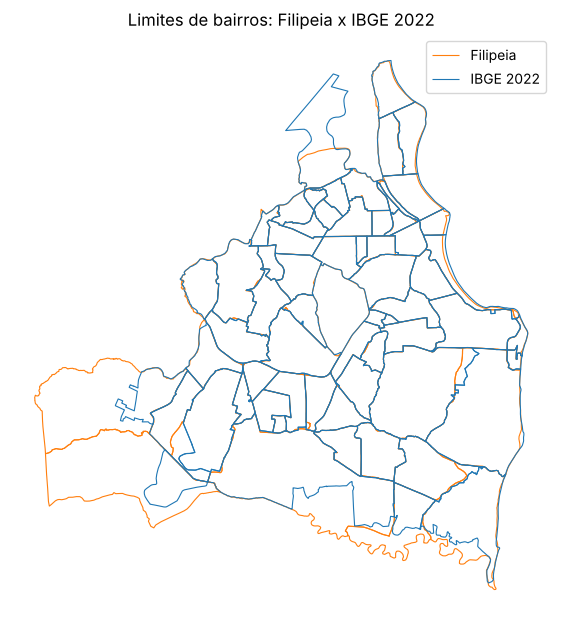

In [4]:
fig, ax = plt.subplots(figsize=(7, 9))
fil.boundary.plot(ax=ax, color='tab:orange', linewidth=0.8, label='Filipeia')
ibge.boundary.plot(ax=ax, color='tab:blue', linewidth=0.8, label='IBGE 2022')
ax.legend(); ax.set_axis_off(); ax.set_title('Limites de bairros: Filipeia x IBGE 2022');

Os bairros do sul (Mussuré, Mumbaba, Gramame) e alguns do norte (Alto do Céu, Indústrias)
divergem muito. Como a população do IBGE foi contada nos polígonos do IBGE, **o mapa e a
densidade usam a malha do IBGE**.

## 3. Limites 2010 x 2022

In [5]:
m10 = censo2010.malha_bairros_2010(setores).to_crs(CRS_METRICO).set_index('cd_bairro')
m22 = ibge.set_index('cd_bairro')
mud = pd.DataFrame({
    'bairro': m22.nm_bairro,
    'km2_2010': [round(m10.geometry[c].area/1e6, 2) if c in m10.index else None for c in m22.index],
    'km2_2022': (m22.area/1e6).round(2),
    'iou': [round(iou(m22.geometry[c], m10.geometry[c]), 3) if c in m10.index else None for c in m22.index],
})
mud.sort_values('iou', na_position='first').head(10)

,bairro,km2_2010,km2_2022,iou
cd_bairro,,,,
2507507064,Mussuré,NaN,2.58,NaN
2507507004,Alto do Céu,2.51,5.99,0.415
2507507008,Indústrias,1.83,3.97,0.459
2507507062,Gramame,7.98,15.55,0.505
2507507041,Muçumagro,1.19,2.13,0.553
2507507063,Mumbaba,2.30,3.01,0.751
2507507049,Roger,1.64,1.31,0.797
2507507060,Barra de Gramame,6.78,7.27,0.827
2507507050,São José,0.36,0.36,0.900


In [6]:
print('setores sem bairro em 2010:', (setores.cd_bairro == censo2010.COD_SEM_BAIRRO).sum(),
      '| pessoas:', setores.loc[setores.cd_bairro == censo2010.COD_SEM_BAIRRO, 'pop'].sum())

setores sem bairro em 2010: 14 | pessoas: 4596


Alguns bairros mudaram de limite entre os censos (Gramame dobrou de área; Mussuré não existia).
A variação 2010→2022 só é mostrada para bairros com IoU ≥ 0,75, e com ressalva entre 0,75 e 0,90.